In [1]:
!pip install roboflow ultralytics opencv-python matplotlib --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 77.8 MB/s eta 0:00:00


In [2]:
from roboflow import Roboflow
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import glob
import numpy as np
import os


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="XvM2cLH3jpIu3ORAYB8p")
project = rf.workspace("sg-icrum").project("simtrafficview5k")
version = project.version(2)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SimTrafficView5K-2 in yolov8:: 100%|██████████| 10012/10012 [00:01<00:00, 6473.73it/s]


In [4]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="XvM2cLH3jpIu3ORAYB8p")
project = rf.workspace("sg-icrum").project("simtrafficview5k")
version = project.version(2)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...


In [5]:
import os
print(os.listdir("/content"))


['.config', 'SimTrafficView5K-2', 'sample_data']


Set Correct data.yaml Path

In [6]:
data_yaml = "/content/SimTrafficView5K-2/data.yaml"
print("data.yaml exists?", os.path.exists(data_yaml))


data.yaml exists? True


Import YOLO (already installed)

In [7]:
!pip install ultralytics --quiet
from ultralytics import YOLO
print("YOLO imported successfully")


YOLO imported successfully


Train YOLO on Your Dataset

In [8]:
model = YOLO("yolov8n.pt")  # Nano model for speed

model.train(
    data=data_yaml,
    epochs=30,
    imgsz=640,
    batch=8,
    name="simtraffic_yolo_model"   # new run name
)


Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SimTrafficView5K-2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=simtraffic_yolo_model, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a61e1b0f980>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

Auto-Find the best.pt File

In [9]:
import os

best_model_path = None
for root, dirs, files in os.walk("/content"):
    for f in files:
        if f == "best.pt":
            best_model_path = os.path.join(root, f)

print("Found best model:", best_model_path)


Found best model: /content/runs/detect/simtraffic_yolo_model/weights/best.pt


best model load

In [10]:
yolo_model = YOLO(best_model_path)
print("Model loaded successfully!")


Model loaded successfully!


VEHICLE TYPE WEIGHTING FUNCTION

In [11]:
def get_vehicle_weight(class_name):
    cname = class_name.lower()
    if "truck" in cname or "lorry" in cname:
        return 3.0
    elif "bus" in cname:
        return 2.5
    elif "car" in cname or "suv" in cname:
        return 1.5
    elif "bike" in cname or "motor" in cname or "scooter" in cname:
        return 1.0
    else:
        return 1.0   # default weight


LANE-WISE COUNTING + WEIGHTED DENSITY

In [12]:
import cv2
import numpy as np

def analyze_lanes(image_path, model, divisor=5):
    """
    Splits into L1,L2,L3,L4 → counts vehicles → computes weighted density → green time.
    """

    img_bgr = cv2.imread(image_path)
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    # Define lanes as quadrants
    mid_x, mid_y = w // 2, h // 2
    lanes = {
        "L1": (0, 0, mid_x, mid_y),
        "L2": (mid_x, 0, w, mid_y),
        "L3": (0, mid_y, mid_x, h),
        "L4": (mid_x, mid_y, w, h)
    }

    raw_counts = {ln: 0 for ln in lanes}
    densities = {ln: 0.0 for ln in lanes}
    type_list = {ln: [] for ln in lanes}

    results = model.predict(image_path, save=False)[0]

    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        cls_id = int(box.cls[0])
        cls_name = results.names[cls_id]
        weight = get_vehicle_weight(cls_name)

        for lane, (x_min, y_min, x_max, y_max) in lanes.items():
            if x_min <= cx < x_max and y_min <= cy < y_max:
                raw_counts[lane] += 1
                densities[lane] += weight
                type_list[lane].append(cls_name)
                break

    # compute final green time
    green_times = {ln: densities[ln] / divisor for ln in lanes}

    return img, lanes, raw_counts, densities, type_list, green_times


RUN LANE ANALYSIS ON YOUR TEST IMAGE

In [13]:
import glob

test_images = glob.glob("/content/SimTrafficView5K-2/test/images/*.jpg")
image_path = test_images[0]

img_lane, lanes, raw_counts, densities, type_list, green_times = analyze_lanes(
    image_path=image_path,
    model=yolo_model,
    divisor=5
)

print("RAW COUNTS:", raw_counts)
print("DENSITIES:", densities)
print("GREEN TIMES:", green_times)



image 1/1 /content/SimTrafficView5K-2/test/images/screenshot_20241228-143712_png.rf.65a1bc1400865904c3da5d001abd44e7.jpg: 640x640 2 Bikes, 6 Buss, 7 Cars, 7 Trucks, 7.3ms
Speed: 1.5ms preprocess, 7.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
RAW COUNTS: {'L1': 1, 'L2': 7, 'L3': 6, 'L4': 8}
DENSITIES: {'L1': 2.5, 'L2': 16.5, 'L3': 11.0, 'L4': 18.5}
GREEN TIMES: {'L1': 0.5, 'L2': 3.3, 'L3': 2.2, 'L4': 3.7}


VISUALIZE LANES + COUNTS + DENSITY + GREEN TIME

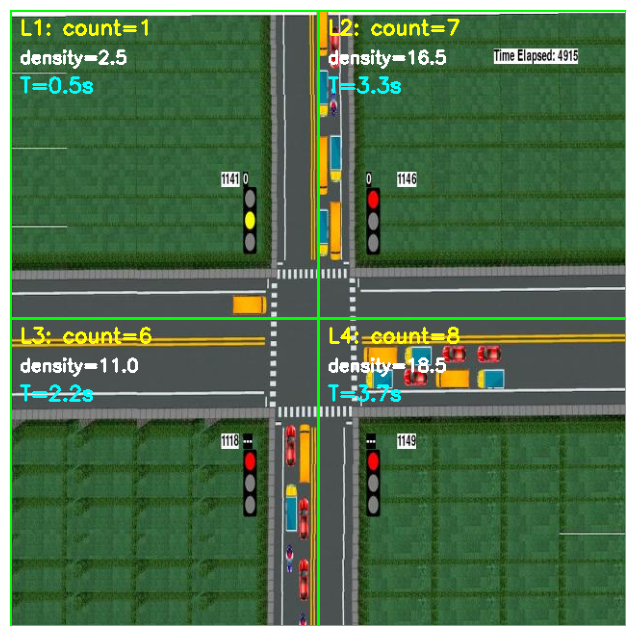

In [14]:
import matplotlib.pyplot as plt

img_vis = img_lane.copy()

for lane, (x1, y1, x2, y2) in lanes.items():
    # Draw lane box
    cv2.rectangle(img_vis, (x1,y1), (x2,y2), (0,255,0), 2)

    # Write info
    text1 = f"{lane}: count={raw_counts[lane]}"
    text2 = f"density={densities[lane]:.1f}"
    text3 = f"T={green_times[lane]:.1f}s"

    cv2.putText(img_vis, text1, (x1+10, y1+25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,0), 2)
    cv2.putText(img_vis, text2, (x1+10, y1+55),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)
    cv2.putText(img_vis, text3, (x1+10, y1+85),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,255), 2)

plt.figure(figsize=(10,8))
plt.imshow(img_vis)
plt.axis("off")
plt.show()


VIDEO PROCESSING (FRAME BY FRAME YOLO + LANE COUNT)

In [15]:
def process_video(video_path, model):
    cap = cv2.VideoCapture(video_path)

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Save frame temporarily
        cv2.imwrite("frame.jpg", frame)

        img, lanes, rc, den, types, gt = analyze_lanes("frame.jpg", model)

        # Visualization
        img_v = img.copy()
        for lane, (x1,y1,x2,y2) in lanes.items():
            cv2.rectangle(img_v, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(img_v, f"{lane}:{rc[lane]} T={gt[lane]:.1f}",
                        (x1+5, y1+30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,0), 2)

        cv2.imshow("Traffic Video", cv2.cvtColor(img_v, cv2.COLOR_RGB2BGR))

        # Quit with q
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()


In [16]:
import time
from IPython.display import clear_output

def simulate_traffic_cycle(green_times):
    lanes = ["L1","L2","L3","L4"]

    for lane in lanes:
        clear_output(wait=True)
        print("============ TRAFFIC SIGNAL SIMULATION ============")
        print(f"{lane} → GREEN for {green_times[lane]:.1f} seconds")
        print("Other lanes → RED")
        time.sleep(green_times[lane])  # simulate actual green time

    clear_output(wait=True)
    print("Cycle complete ✔")


Add this function to your notebook

In [17]:
from google.colab.patches import cv2_imshow
import cv2
import time

def process_video_colab(video_path, model):
    cap = cv2.VideoCapture(video_path)

    frame_no = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            print("Video finished.")
            break

        frame_no += 1

        # Save frame temporarily
        temp_path = "frame_temp.jpg"
        cv2.imwrite(temp_path, frame)

        # Analyze lanes using your YOLO model
        img, lanes, rc, den, types, gt = analyze_lanes(temp_path, model)

        # Draw overlays
        img_v = img.copy()
        for lane, (x1,y1,x2,y2) in lanes.items():
            cv2.rectangle(img_v, (x1,y1), (x2,y2), (0,255,0), 2)
            text = f"{lane}: {rc[lane]} | T={gt[lane]:.1f}s"
            cv2.putText(img_v, text, (x1+10, y1+30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,0), 2)

        # Show one frame at a time inside notebook
        print(f"Frame {frame_no}")
        cv2_imshow(cv2.cvtColor(img_v, cv2.COLOR_RGB2BGR))

        # Control speed (0.1 sec delay)
        time.sleep(0.1)

    cap.release()
    print("Processing completed.")


video processing when we run

In [18]:
process_video_colab("/content/traffic.mp4", yolo_model)


Video finished.
Processing completed.


Take one sample frame and show lane stats clearly

In [19]:
import glob

# take one test image from dataset
test_images = glob.glob("/content/SimTrafficView5K-2/test/images/*.jpg")
image_path = test_images[0]
print("Using image:", image_path)

img_lane, lanes, raw_counts, densities, type_list, green_times = analyze_lanes(
    image_path=image_path,
    model=yolo_model,
    divisor=5
)

print("RAW COUNTS:", raw_counts)
print("DENSITIES:", densities)
print("GREEN TIMES:", green_times)


Using image: /content/SimTrafficView5K-2/test/images/screenshot_20241228-143712_png.rf.65a1bc1400865904c3da5d001abd44e7.jpg

image 1/1 /content/SimTrafficView5K-2/test/images/screenshot_20241228-143712_png.rf.65a1bc1400865904c3da5d001abd44e7.jpg: 640x640 2 Bikes, 6 Buss, 7 Cars, 7 Trucks, 11.3ms
Speed: 2.2ms preprocess, 11.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
RAW COUNTS: {'L1': 1, 'L2': 7, 'L3': 6, 'L4': 8}
DENSITIES: {'L1': 2.5, 'L2': 16.5, 'L3': 11.0, 'L4': 18.5}
GREEN TIMES: {'L1': 0.5, 'L2': 3.3, 'L3': 2.2, 'L4': 3.7}


vizualize it

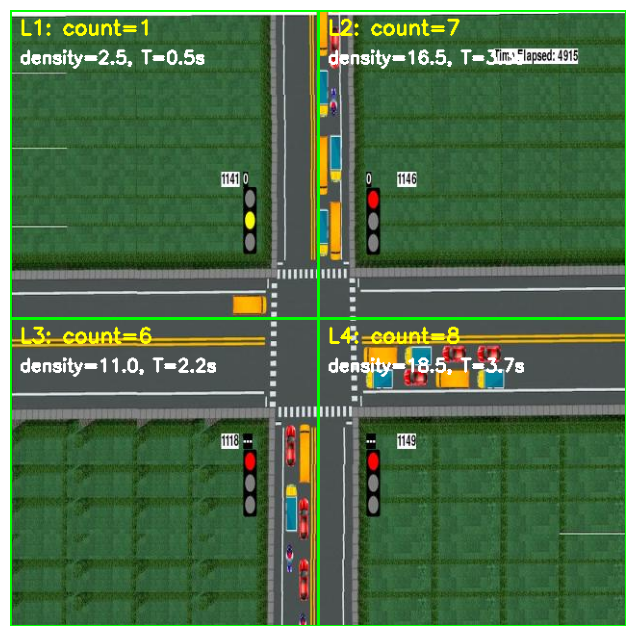

In [20]:
import matplotlib.pyplot as plt
import cv2

img_vis = img_lane.copy()

for lane, (x1, y1, x2, y2) in lanes.items():
    cv2.rectangle(img_vis, (x1,y1), (x2,y2), (0,255,0), 2)
    text1 = f"{lane}: count={raw_counts[lane]}"
    text2 = f"density={densities[lane]:.1f}, T={green_times[lane]:.1f}s"
    cv2.putText(img_vis, text1, (x1+10, y1+25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,0), 2)
    cv2.putText(img_vis, text2, (x1+10, y1+55),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)

plt.figure(figsize=(10,8))
plt.imshow(img_vis)
plt.axis("off")
plt.show()


Run traffic-light simulation once using that image

In [21]:
import time
from IPython.display import clear_output

def simulate_traffic_cycle(green_times):
    lanes = ["L1","L2","L3","L4"]
    for lane in lanes:
        clear_output(wait=True)
        print("========== TRAFFIC SIGNAL SIMULATION ==========")
        print(f"Lane {lane} → GREEN for {green_times[lane]:.1f} seconds")
        print("Other lanes → RED")
        time.sleep(green_times[lane])
    clear_output(wait=True)
    print("Cycle complete ✅")


now run

In [22]:
simulate_traffic_cycle(green_times)


Cycle complete ✅


the output for this will dispaly like this ========== TRAFFIC SIGNAL SIMULATION ==========
Lane L1 → GREEN for 3.2 seconds
Other lanes → RED
...
Lane L2 → GREEN for 1.4 seconds
...
Cycle complete ✅


Find best.pt & save in fixed path

In [25]:
best_model = None

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f == "best.pt":
            best_model = os.path.join(root, f)

print("Found best model at:", best_model)

# Save in fixed location
fixed_best_path = "/content/best_simtraffic.pt"
shutil.copy(best_model, fixed_best_path)

print("Saved final best model to:", fixed_best_path)


Found best model at: /content/runs/detect/simtraffic_yolo_model/weights/best.pt
Saved final best model to: /content/best_simtraffic.pt


Weighted vehicle logic

In [26]:
import cv2
import numpy as np
from ultralytics import YOLO

def get_vehicle_weight(cls):
    cls = cls.lower()
    if "truck" in cls: return 3.0
    if "bus" in cls:   return 2.5
    if "car" in cls:   return 1.5
    if "bike" in cls:  return 1.0
    return 1.0


Lane analyzer

In [28]:
def analyze_lanes(img_rgb, model, divisor=5):
    h, w, _ = img_rgb.shape
    mid_x, mid_y = w//2, h//2

    lanes = {
        "L1": (0, 0, mid_x, mid_y),
        "L2": (mid_x, 0, w, mid_y),
        "L3": (0, mid_y, mid_x, h),
        "L4": (mid_x, mid_y, w, h)
    }

    counts = {k:0 for k in lanes}
    densities = {k:0.0 for k in lanes}

    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    results = model.predict(img_bgr, save=False)[0]

    for box in results.boxes:
        x1,y1,x2,y2 = box.xyxy[0].tolist()
        cx,cy = (x1+x2)/2 , (y1+y2)/2
        cls = results.names[int(box.cls[0])]
        weight = get_vehicle_weight(cls)

        for lane,(x_min,y_min,x_max,y_max) in lanes.items():
            if x_min <= cx < x_max and y_min <= cy < y_max:
                counts[lane]+=1
                densities[lane]+=weight

    green = {k: densities[k]/divisor for k in lanes}

    return lanes, counts, densities, green, results


Build final prediction function for Gradio

In [29]:
yolo_model = YOLO("/content/best_simtraffic.pt")

def predict_traffic(img):
    if img is None:
        return None, "Upload an image."

    img = img.copy()
    lanes, counts, densities, green, results = analyze_lanes(img, yolo_model)

    h, w, _ = img.shape
    mid_x, mid_y = w//2, h//2

    # Draw YOLO boxes
    for box in results.boxes:
        x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
        cls = results.names[int(box.cls[0])]
        conf = float(box.conf[0])
        cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(img,f"{cls} {conf:.2f}",(x1,y1-5),
                    cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)

    # Draw lane cross lines
    cv2.line(img,(mid_x,0),(mid_x,h),(0,255,255),2)
    cv2.line(img,(0,mid_y),(w,mid_y),(0,255,255),2)

    # Lane labels
    for ln,(x1,y1,x2,y2) in lanes.items():
        cv2.putText(img,f"{ln}: {counts[ln]}",(x1+10,y1+25),
                    cv2.FONT_HERSHEY_SIMPLEX,0.8,(255,255,0),2)
        cv2.putText(img,f"d={densities[ln]:.1f} T={green[ln]:.1f}s",(x1+10,y1+55),
                    cv2.FONT_HERSHEY_SIMPLEX,0.7,(255,255,255),2)

    summary = "\n".join([
        f"{ln}: count={counts[ln]}, density={densities[ln]:.1f}, green={green[ln]:.1f}s"
        for ln in ["L1","L2","L3","L4"]
    ])

    return img, summary


In [47]:
import gradio as gr

bg_image = "https://parquery.com/wp-content/uploads/2022/05/CamerasTrafficLights.jpg"

css = f"""
body {{
  background: url('{bg_image}') no-repeat center center fixed;
  background-size: cover;
  font-family: 'Segoe UI', sans-serif;
}}

.gradio-container {{
  background: rgba(0,0,0,0.55) !important;
  padding: 20px;
  border-radius: 20px;
}}

h1 {{
  color: #00ffea;
  text-shadow: 0 0 10px black;
}}
"""

with gr.Blocks(css=css) as demo:
    gr.Markdown("<h1>🚦 Smart Density-Based Traffic Signal System</h1>")

    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="numpy", label="Upload Traffic Image")
            btn = gr.Button("Analyze Traffic", variant="primary")

        with gr.Column():
            out_img = gr.Image(label="Detection Output")
            out_txt = gr.Textbox(label="Lane Summary", lines=8)

    btn.click(predict_traffic, inputs=inp, outputs=[out_img, out_txt])

demo.launch(debug=True, auth=("admin", "secret"))


The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://6f876d9614f91ee890.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://6f876d9614f91ee890.gradio.live


streamlit code


upload image for background

In [75]:
from google.colab import files
uploaded = files.upload()


Saving d1.jpg to d1 (2).jpg


In [76]:
import os
os.listdir("/content")


['.config',
 '.gradio',
 'SimTrafficView5K-2',
 '.ipynb_checkpoints',
 'streamlit_app.py',
 'yolo11n.pt',
 'd1 (2).jpg',
 'd1 (1).jpg',
 'best_simtraffic.pt',
 'yolov8n.pt',
 'runs',
 'd1.jpg',
 'sample_data']

In [77]:
%%writefile streamlit_app.py
import streamlit as st
import cv2
import numpy as np
from ultralytics import YOLO
from PIL import Image
import base64

##############################
# Load YOLO model
##############################
model = YOLO("yolov8n.pt")   # or your best model


###################################
# Background CSS (Using d1.jpg)
###################################

def get_base64_image(image_path):
    with open(image_path, "rb") as f:
        data = f.read()
    return base64.b64encode(data).decode()

background_img = get_base64_image("/content/d1.jpg")


page_bg = f"""
<style>

/* Background */
[data-testid="stAppViewContainer"] {{
    background-image: url("data:image/jpeg;base64,{background_img}");
    background-size: cover;
    background-position: center;
    background-attachment: fixed;
    background-repeat: no-repeat;
}}

/* Transparent Header */
[data-testid="stHeader"] {{
    background: rgba(0,0,0,0);
}}

/* Animated white heading using CSS Keyframes */
@keyframes glow {{
    0% {{ text-shadow: 0 0 10px #ffffff; }}
    50% {{ text-shadow: 0 0 25px #00eaff, 0 0 50px #00eaff; }}
    100% {{ text-shadow: 0 0 10px #ffffff; }}
}}

h1 {{
    color: #ffffff !important;
    font-size: 42px;
    font-weight: 900;
    text-align: center;
    animation: glow 2s infinite ease-in-out;
    letter-spacing: 2px;
}}

/* Glass Effect Box */
.main-block {{
    background: rgba(0, 0, 0, 0.55);
    padding: 30px;
    border-radius: 20px;
    backdrop-filter: blur(10px);
    box-shadow: 0px 0px 30px rgba(0,255,255,0.4);
}}

/* Buttons */
.stButton>button {{
    width: 100%;
    border-radius: 10px;
    padding: 10px;
    font-weight: bold;
    color: white;
    font-size: 16px;
    background: linear-gradient(90deg, #0077ff, #00ffaa);
    border: none;
    box-shadow: 0px 0px 10px black;
}}

</style>
"""

st.markdown(page_bg, unsafe_allow_html=True)

###################################
# Header
###################################
st.markdown("<h1>🚦 Smart Density-Based Traffic Signal System</h1>", unsafe_allow_html=True)


###################################
# Functions
###################################

def count_lanes(img, results):
    h, w, _ = img.shape
    mid_x, mid_y = w//2, h//2

    lanes = [0, 0, 0, 0]

    for r in results:
        for box in r.boxes.xyxy:
            x1, y1, x2, y2 = box.tolist()
            cx = (x1 + x2) / 2
            cy = (y1 + y2) / 2

            # 4 Quadrants = 4 Lanes
            if cx < mid_x and cy < mid_y: lanes[0] += 1
            elif cx > mid_x and cy < mid_y: lanes[1] += 1
            elif cx < mid_x and cy > mid_y: lanes[2] += 1
            else: lanes[3] += 1

    return lanes


def simulate_signals(lanes):
    output = "🚦 Traffic Signal Simulation\n\n"
    for i, c in enumerate(lanes):
        green = round(c / 5, 2)
        output += f"L{i+1}: {c} vehicles → Green Time = {green}s\n"
    return output


###################################
# UI Layout
###################################

with st.container():
    st.markdown("<div class='main-block'>", unsafe_allow_html=True)

    uploaded = st.file_uploader("📤 Upload Traffic Image", type=["jpg", "png", "jpeg"])

    if uploaded:
        img = Image.open(uploaded)
        img_np = np.array(img)

        st.image(img, caption="Uploaded Image", use_column_width=True)

        # Analyze Button
        if st.button("🔍 Analyze Traffic"):
            results = model(img_np)
            lanes = count_lanes(img_np, results)

            annotated = results[0].plot()
            st.image(annotated, caption="🚗 Detection Output", use_column_width=True)

            lane_text = "\n".join([f"L{i+1}: {c} vehicles" for i, c in enumerate(lanes)])
            st.text_area("Lane Summary", lane_text, height=120)

        # Simulation Button
        if st.button("🚦 Simulate Signals"):
            lanes = count_lanes(img_np, model(img_np))
            sim = simulate_signals(lanes)
            st.text_area("Traffic Light Simulation", sim, height=140)

    st.markdown("</div>", unsafe_allow_html=True)


Overwriting streamlit_app.py


In [78]:
NGROK_AUTH_TOKEN = "35ui53Cspr4zqYvVULCF7x2IFCD_7XzMRYA3EWdWEvuwcHezc"


In [79]:
from pyngrok import ngrok

ngrok.set_auth_token(NGROK_AUTH_TOKEN)


In [ ]:
# Run streamlit via ngrok tunnel
public_url = ngrok.connect(8501)
print("STREAMLIT URL:", public_url)

!streamlit run streamlit_app.py #--server.port 8501


STREAMLIT URL: NgrokTunnel: "https://sigmoidally-archegonial-norine.ngrok-free.dev" -> "http://localhost:8501"





  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.169.65:8501



(No Overlap)

In [33]:
def draw_lane_info(img, lanes, counts, densities, green):
    for lane,(x1,y1,x2,y2) in lanes.items():

        # Draw lane box
        cv2.rectangle(img,(x1,y1),(x2,y2),(255,255,0),2)

        # Position labels OUTSIDE the lane (no overlap)
        text_y1 = y1 - 40 if y1 - 40 > 20 else y2 + 20

        cv2.putText(
            img,
            f"{lane}: {counts[lane]}",
            (x1 + 10, text_y1),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0,255,255),
            2
        )

        cv2.putText(
            img,
            f"d={densities[lane]:.1f} T={green[lane]:.1f}s",
            (x1 + 10, text_y1 + 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255,255,255),
            2
        )
    return img


Updated predict_traffic() with clean overlay

In [34]:
def predict_traffic(img):
    if img is None:
        return None, "Please upload an image"

    img = img.copy()
    lanes, counts, densities, green, results = analyze_lanes(img, yolo_model)

    # YOLO vehicle boxes
    for box in results.boxes:
        x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
        cls = results.names[int(box.cls[0])]
        conf = float(box.conf[0])
        cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(img,f"{cls} {conf:.2f}",(x1,y1-8),
                    cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)

    # Lane lines
    h,w,_ = img.shape
    mid_x,mid_y = w//2, h//2
    cv2.line(img,(mid_x,0),(mid_x,h),(0,255,255),2)
    cv2.line(img,(0,mid_y),(w,mid_y),(0,255,255),2)

    # NEW improved placement
    img = draw_lane_info(img, lanes, counts, densities, green)

    summary = "\n".join([
        f"{ln}: count={counts[ln]}, density={densities[ln]:.1f}, green={green[ln]:.1f}s"
        for ln in ["L1","L2","L3","L4"]
    ])

    return img, summary


adjust analyze_lanes

In [40]:
def analyze_lanes(img_rgb, model, divisor=5):
    h, w, _ = img_rgb.shape
    mid_x, mid_y = w // 2, h // 2

    lanes = {
        "L1": (0, 0, mid_x, mid_y),
        "L2": (mid_x, 0, w, mid_y),
        "L3": (0, mid_y, mid_x, h),
        "L4": (mid_x, mid_y, w, h)
    }

    counts = {k: 0 for k in lanes}
    densities = {k: 0.0 for k in lanes}

    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    results = model.predict(img_bgr, save=False)[0]

    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        cls_name = results.names[int(box.cls[0])]
        weight = get_vehicle_weight(cls_name)

        for lane, (x_min, y_min, x_max, y_max) in lanes.items():
            if x_min <= cx < x_max and y_min <= cy < y_max:
                counts[lane] += 1
                densities[lane] += weight
                break

    green = {ln: densities[ln] / divisor for ln in lanes}

    # IMPORTANT: return these 4 things + results
    return lanes, counts, densities, green, results


no overlapping labels

In [42]:
def draw_lane_info(img, lanes, counts, densities, green):
    for lane, (x1, y1, x2, y2) in lanes.items():
        # lane rectangle
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 0), 2)

        # put text outside lane to avoid overlap
        text_y1 = y1 - 40 if y1 - 40 > 20 else y2 + 20

        cv2.putText(img, f"{lane}: {counts[lane]}",
                    (x1 + 10, text_y1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8,
                    (0, 255, 255), 2)

        cv2.putText(img, f"d={densities[lane]:.1f} T={green[lane]:.1f}s",
                    (x1 + 10, text_y1 + 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                    (255, 255, 255), 2)
    return img


In [43]:
def predict_traffic(img):
    if img is None:
        return None, "Please upload an image"

    img = img.copy()
    lanes, counts, densities, green, results = analyze_lanes(img, yolo_model)

    # YOLO boxes WITHOUT text
    for box in results.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # cross lines
    h, w, _ = img.shape
    mid_x, mid_y = w // 2, h // 2
    cv2.line(img, (mid_x, 0), (mid_x, h), (0, 255, 255), 2)
    cv2.line(img, (0, mid_y), (w, mid_y), (0, 255, 255), 2)

    # lane info outside
    img = draw_lane_info(img, lanes, counts, densities, green)

    summary = "\n".join(
        f"{ln}: count={counts[ln]}, density={densities[ln]:.1f}, green={green[ln]:.1f}s"
        for ln in ["L1", "L2", "L3", "L4"]
    )

    return img, summary


Create traffic-light simulation function

In [44]:
def simulate_signals(img):
    if img is None:
        return "Please upload an image first."

    img = img.copy()
    _, counts, densities, green, _ = analyze_lanes(img, yolo_model)

    # order of lanes in cycle
    order = ["L1", "L2", "L3", "L4"]

    lines = []
    lines.append("🚦 Traffic Signal Cycle (Green → Yellow → Next Lane)\n")

    for lane in order:
        g = max(green[lane], 0.1)  # avoid 0 seconds
        y = max(g * 0.3, 0.5)      # yellow ~30% of green

        # build emoji line
        state_lines = []
        for ln in order:
            if ln == lane:
                state_lines.append(f"{ln}: 🟢 (G={g:.1f}s)")
            else:
                state_lines.append(f"{ln}: 🔴")
        lines.append(" | ".join(state_lines))

        # yellow phase line
        yellow_line = " | ".join(
            f"{ln}: 🟡 (Y={y:.1f}s)" if ln == lane else f"{ln}: 🔴"
            for ln in order
        )
        lines.append(yellow_line)
        lines.append("")  # blank line between lanes

    lines.append("✅ Cycle complete (simulated).")
    return "\n".join(lines)


Update your Gradio UI to include simulation

In [45]:
bg_image = "https://parquery.com/wp-content/uploads/2022/05/CamerasTrafficLights.jpg"

css = f"""
body {{
  background: url('{bg_image}') no-repeat center center fixed;
  background-size: cover;
  font-family: 'Segoe UI', sans-serif;
}}

.gradio-container {{
  background: rgba(0,0,0,0.55) !important;
  padding: 20px;
  border-radius: 20px;
}}

h1 {{
  color: #00ffea;
  text-shadow: 0 0 10px black;
}}
"""


Button 1 → Analyze Traffic (image + lane summary)

Button 2 → Simulate Signals (text only)

In [48]:
!pip install streamlit pyngrok --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 89.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 141.4 MB/s eta 0:00:00


In [46]:
with gr.Blocks(css=css) as demo:
    gr.Markdown("<h1>🚦 Smart Density-Based Traffic Signal System</h1>")

    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Image(type="numpy", label="Upload Traffic Image")
            btn_analyze = gr.Button("Analyze Traffic", variant="primary")
            btn_sim = gr.Button("Simulate Signals (Green-Yellow-Red)")

        with gr.Column(scale=1.3):
            out_img = gr.Image(label="Detection Output")
            out_txt = gr.Textbox(label="Lane Summary", lines=8)
            sim_txt = gr.Textbox(label="Traffic Light Simulation", lines=10)

    # connect buttons
    btn_analyze.click(
        fn=predict_traffic,
        inputs=inp,
        outputs=[out_img, out_txt]
    )

    btn_sim.click(
        fn=simulate_signals,
        inputs=inp,
        outputs=sim_txt
    )

demo.launch(debug=True, auth=("admin", "secret"))


The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
'scale' value should be an integer. Using 1.3 will cause issues.


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7b4bcd05c25a1ceb10.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/h11_impl.py", line 403, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 60, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1133, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 113, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py",


0: 640x640 5 Bikes, 5 Buss, 6 Cars, 8 Trucks, 44.1ms
Speed: 4.1ms preprocess, 44.1ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 5 Bikes, 5 Buss, 6 Cars, 8 Trucks, 10.8ms
Speed: 3.6ms preprocess, 10.8ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 5 Bikes, 5 Buss, 6 Cars, 8 Trucks, 7.4ms
Speed: 2.8ms preprocess, 7.4ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 5 Bikes, 5 Buss, 6 Cars, 8 Trucks, 9.4ms
Speed: 4.0ms preprocess, 9.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7b4bcd05c25a1ceb10.gradio.live
